<a href="https://colab.research.google.com/github/IvanZinchenko3214/dap-2024/blob/main/les06/rep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets

diabetes = datasets.load_diabetes()

print(diabetes.DESCR)

print("\nПризнаки:", diabetes.feature_names)
print("Форма данных:", diabetes.data.shape)
print("Форма целевого значения:", diabetes.target.shape)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [2]:

df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
df.info()

print("Пропуски по столбцам:\n", df.isnull().sum())

print("\nТипы данных:\n", df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
Пропуски по столбцам:
 age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Типы данных:
 age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target   

target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


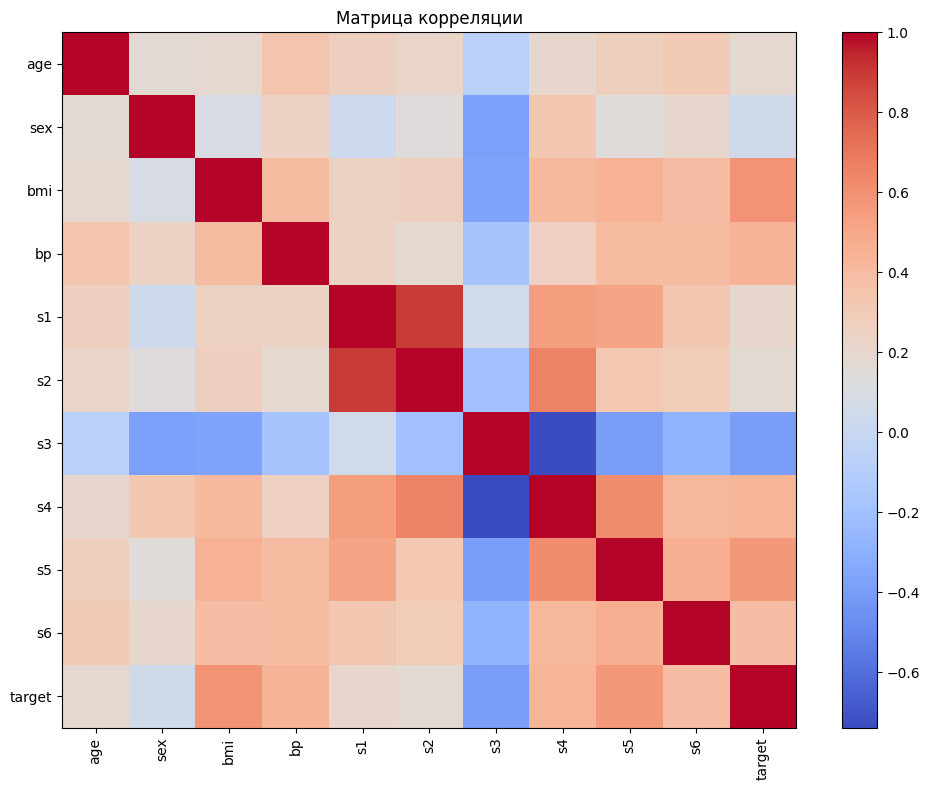

In [4]:
corr_matrix = df.corr()
print(corr_matrix['target'].sort_values(ascending=False))

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap='coolwarm', aspect='auto')
plt.colorbar()
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.title('Матрица корреляции')
plt.tight_layout()
plt.show()

Признак с максимальной корреляцией: bmi r = 0.5864501344746885


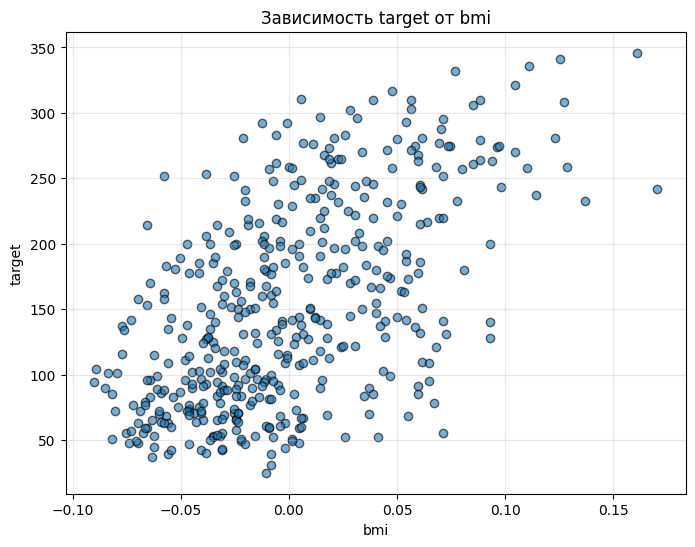

In [5]:
top_feature = corr_matrix['target'].drop('target').abs().idxmax()
print("Признак с максимальной корреляцией:", top_feature,
      "r =", corr_matrix.loc[top_feature, 'target'])

plt.figure(figsize=(8, 6))
plt.scatter(df[top_feature], df['target'], alpha=0.6, edgecolor='k')
plt.xlabel(top_feature)
plt.ylabel('target')
plt.title(f'Зависимость target от {top_feature}')
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
top5_features = (corr_matrix['target'].drop('target')
                 .abs().sort_values(ascending=False).head(5).index.tolist())
print("Топ-5 признаков:", top5_features)

X = df[top5_features].values
y = df['target'].values

Топ-5 признаков: ['bmi', 's5', 'bp', 's4', 's3']


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

print("Коэффициенты:", dict(zip(top5_features, model.coef_)))
print("Свободный член:", model.intercept_)

Обучающая выборка: (331, 5)
Тестовая выборка: (111, 5)
Коэффициенты: {'bmi': np.float64(583.8741165576641), 's5': np.float64(456.0746599275144), 'bp': np.float64(331.7853601420305), 's4': np.float64(-166.13810498936493), 's3': np.float64(-358.64107421832983)}
Свободный член: 151.69449510537066


In [8]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"RMSE: {rmse:.4f}")

r2 = r2_score(y_test, y_pred)
print(f"R²: {r2:.4f}")

RMSE: 53.7846
R²: 0.4769
